# Deconvolving the BBH Merger Rate

The BBH merger rate is the progenitor formation rate convolved with the delay time distribution. Given a merger rate and an assumed delay time distribution, we solve for the formation rate directly, without assuming its functional form. A delay time distribution that requires a negative formation rate is incompatible with the merger rate.

This notebook sets up the method so it can be used with any delay time distribution and merger rate posterior, and applies it to the GWTC-4.0 merger rate with power-law and COMPAS delay time distributions to make the results and figures of "Forbidden Formation Histories: The Binary Black Hole Merger Rate Disfavours Long Delay Times".

# Initialization

Import packages and set the plotting style. The solver and the COMPAS processing live in `deconvolution.py` and `compas_delay_times.py`. Requires Python 3 with numpy, scipy, matplotlib, seaborn, astropy and h5py (tested versions in `requirements.txt`).

In [59]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.offsetbox import VPacker, HPacker, TextArea, DrawingArea, AnchoredOffsetbox
from astropy import units as u

from deconvolution import cosmo, Grid, solve, fit_slope, alpha_at, weighted_percentiles, z_from_age
from compas_delay_times import load_compas, MSSFR_FIDUCIAL, weights_at, delay_time_distribution

import seaborn as sns
sns.set_context('paper', font_scale = 1.5)
sns.set_palette('colorblind')
sns.set_style({'font.family':'serif', 'font.serif':'Times New Roman'})

os.makedirs('figures', exist_ok=True)

# Data

Read in the LVK GWTC-4.0 B-spline merger rate draws and the COMPAS delay time distributions and yields (Fishbach & van Son 2023).

In [60]:
# read in O4 merger rate data
with h5py.File('data/Rates_redshift_O4_bspline.h5', 'r') as f:
    zs_O4 = f['zs'][:]
    rates_O4 = f['R_zs'][:]          # (redshift, draw) [Gpc^-3 yr^-1]
times_O4 = cosmo.age(zs_O4).to_value(u.yr)
n_draws = rates_O4.shape[1]

# COMPAS delay times and yields: from https://zenodo.org/records/10019887
compas = load_compas('data/10019887/Output')
models = list(compas)
print(f"{n_draws} merger rate draws, {len(models)} COMPAS models")

5000 merger rate draws, 35 COMPAS models


# The method

The grid has N = 1000 steps from 10 Myr to z = 0.008 (Section 2.1), and each delay time distribution is integrated over the grid's own steps (Eq. 2). To use your own delay time distribution, tabulate it in Gyr and pass it to `grid.binned_kernel(t, p)`, build the convolution matrix with `grid.forward_matrix`, and `solve` returns the formation rate of every merger rate draw; `grid.compatibility` gives the fraction of draws whose formation rate is non-negative (Eq. 8).

For the COMPAS models, the delay time distribution depends on formation time, p(tau | t_form) = sum_k w_k(t_form) p_k(tau), with the fiducial metallicity history of van Son et al. (2023) (Eqs. 5-7).

In [61]:
grid = Grid(times_O4)
Rm0 = grid.merger_rate(rates_O4)                  # all draws, R_merge(z > 1.5) = 0
print(f"dt = {grid.dt / 1e6:.2f} Myr, positivity window 0.1 < z < 1.5 has {grid.window.sum()} steps")

# check: the formation rate reproduces the merger rate when convolved forward again
K = grid.forward_matrix(grid.powerlaw_kernel(-1.0))
print(f"max |K R_form - R_merge| / max R_merge = {np.max(np.abs(K @ solve(K, Rm0[:, 0]) - Rm0[:, 0])) / Rm0[:, 0].max():.1e}")

dt = 13.68 Myr, positivity window 0.1 < z < 1.5 has 598 steps
max |K R_form - R_merge| / max R_merge = 1.9e-16


In [62]:

# class kernels on the grid, and the progenitor mix w_k at every formation step
class_kernels = {m: np.vstack([grid.binned_kernel(compas[m]['t'], p) for p in compas[m]['p']]) for m in models}
weights = {m: weights_at(compas[m], MSSFR_FIDUCIAL, grid.z) for m in models}

def compas_matrix(m):
    # convolution matrix of a COMPAS model, formation-time dependent kernel
    return grid.forward_matrix(class_kernels[m], weights[m])

Fitted power-law index of each COMPAS model (Section 4.1). The fit is repeated at 30 formation redshifts across 0.1 < z_f < 1.5; we keep the median and the range.

In [63]:
steps = np.where(grid.window)[0][np.linspace(0, grid.window.sum() - 1, 30).astype(int)]
alpha_fits = np.array([[fit_slope(compas[m]['t'], delay_time_distribution(compas[m], weights[m][:, j])) for j in steps]
                       for m in models])
alpha_med = np.median(alpha_fits, axis=1)
alpha_lo, alpha_hi = alpha_fits.min(axis=1), alpha_fits.max(axis=1)
print(f"largest change of the fitted alpha over 0.1 < z_f < 1.5: {np.max(alpha_hi - alpha_lo):.3f}")

largest change of the fitted alpha over 0.1 < z_f < 1.5: 0.068


# Forbidden formation histories

Fig. 1: one GWTC-4.0 draw deconvolved with p(tau) ∝ tau^-1 and tau^-1.5. The required merger rate reconvolves the formation rate after freezing it to zero where it first goes negative.

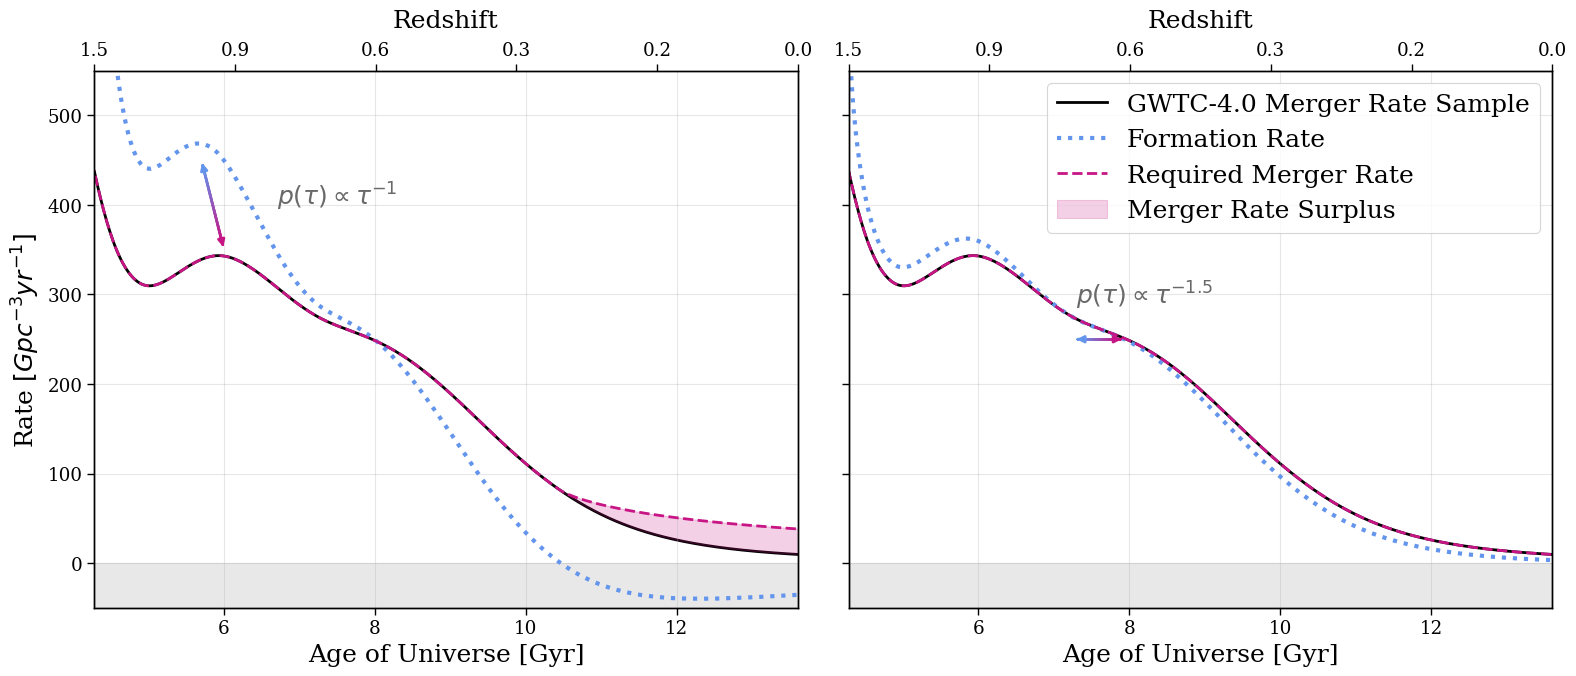

In [64]:
def draw_gradient_arrow(ax, start, end, lw=2):
    # double-headed arrow fading from blue (formation) to pink (merger)
    cmap = LinearSegmentedColormap.from_list('fade', ['cornflowerblue', 'mediumvioletred'])
    d = np.subtract(end, start)
    pad = 0.1 * d
    p0, p1 = np.add(start, pad), np.subtract(end, pad)
    x, y = np.linspace(p0[0], p1[0], 100), np.linspace(p0[1], p1[1], 100)
    pts = np.array([x, y]).T.reshape(-1, 1, 2)
    lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], axis=1), cmap=cmap, linewidth=lw, capstyle='round')
    lc.set_array(np.linspace(0, 1, 100))
    ax.add_collection(lc)
    ax.annotate('', xy=end, xytext=p1, arrowprops=dict(arrowstyle='-|>', lw=lw, color='mediumvioletred', mutation_scale=10))
    ax.annotate('', xy=start, xytext=p0, arrowprops=dict(arrowstyle='-|>', lw=lw, color='cornflowerblue', mutation_scale=10))

idx = 2715                                        # the example draw
Rm = Rm0[:, idx]
t_gyr = grid.T / 1e9
arrow_locs = [(5.7, 450, 6, 350, 7.5, 400), (7.3, 250, 7.9, 250, 8.2, 290)]   # arrow start, end, label position

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, a, loc in zip(axes, [-1, -1.5], arrow_locs):
    K = grid.forward_matrix(grid.powerlaw_kernel(a))
    Rf = solve(K, Rm)

    # freeze the formation rate to zero from its first negative value in the window
    neg = np.where(grid.window & (Rf < 0))[0]
    Rf_frozen = Rf.copy()
    if len(neg):
        Rf_frozen[neg[0]:] = 0
    Rm_req = K @ Rf_frozen

    ax.axhspan(-50, 0, color='lightgray', alpha=0.5, zorder=0)
    ax.plot(t_gyr, Rm, color='k', lw=2, label='GWTC-4.0 Merger Rate Sample', zorder=0)
    ax.plot(t_gyr, Rf, ':', lw=3, color='cornflowerblue', label='Formation Rate')
    ax.plot(t_gyr, Rm_req, color='mediumvioletred', ls='--', lw=2, label='Required Merger Rate')
    ax.fill_between(t_gyr, Rm, Rm_req, where=Rm_req > Rm, color='mediumvioletred', alpha=0.2, label='Merger Rate Surplus')
    draw_gradient_arrow(ax, loc[:2], loc[2:4])
    ax.text(*loc[4:], rf'$p(\tau) \propto \tau^{{{a}}}$', ha='center', fontsize=18, color='dimgray')

    lims = (times_O4[-1] / 1e9, times_O4[0] / 1e9 - 0.075)
    ax.set_xlim(lims)
    ax.set_ylim(-50, 550)
    ax.set_xlabel('Age of Universe [Gyr]', fontsize=18)
    ax.grid(alpha=0.3)
    ax2 = ax.twiny()
    ax2.set_xlim(lims)
    ticks = np.linspace(*lims, 6)
    ax2.set_xticks(ticks)
    ax2.set_xticklabels([f'{z:.1f}' for z in z_from_age(ticks * 1e9)])
    ax2.set_xlabel('Redshift', fontsize=18, labelpad=10)

axes[0].set_ylabel(r'Rate $[Gpc^{-3} yr^{-1}]$', fontsize=18)
axes[1].legend(loc='upper right', fontsize=18)
plt.tight_layout()
plt.savefig('figures/quota.png', dpi=300, bbox_inches='tight')
plt.show()

Fig. 2: formation rates from random (draw, COMPAS model) pairs, 500 physical and 500 unphysical, with the Katsianis et al. (2021) SFR scaled by 1e-6 per solar mass.

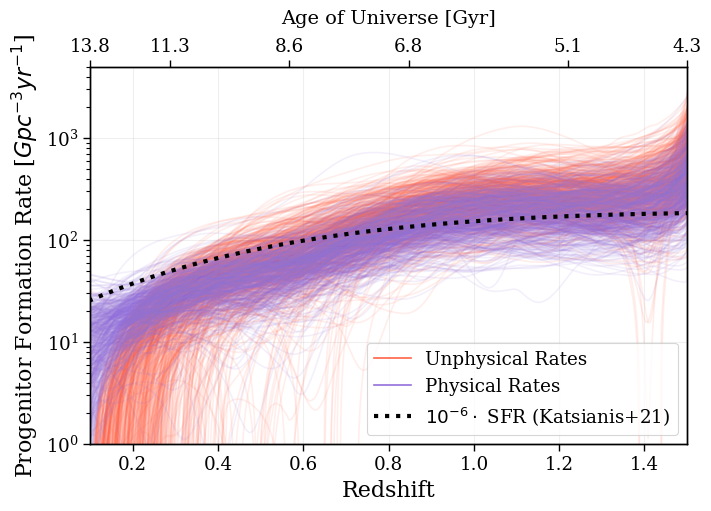

In [65]:
rng = np.random.default_rng(1)
physical, unphysical = [], []
while len(physical) < 500 or len(unphysical) < 500:
    m = models[rng.integers(len(models))]
    Rf = solve(compas_matrix(m), Rm0[:, rng.integers(0, n_draws, size=10)])
    for rate, ok in zip(Rf.T, grid.is_physical(Rf)):
        (physical if ok else unphysical).append(rate)
physical, unphysical = physical[:500], unphysical[:500]

# Katsianis+21 SFR shape, T^1.83 exp(-0.48 T) with T in Gyr, times 1e-6 BBH progenitors per Msun
T_sfr = np.linspace(0.1, 13.7, 200)
sfr = 0.1 * 1e-6 * T_sfr**1.83 * np.exp(-0.48 * T_sfr) * 1e9
z_sfr = z_from_age(T_sfr * 1e9)

z_ticks = np.array([0, 0.2, 0.5, 0.8, 1.2, 1.5])
fig, ax1 = plt.subplots(figsize=(7, 5), constrained_layout=True)
for i, rate in enumerate(unphysical):
    ax1.plot(grid.z, rate, color='tomato', alpha=0.1, label='Unphysical Rates' if i == 0 else None)
for i, rate in enumerate(physical):
    ax1.plot(grid.z, rate, color='mediumpurple', alpha=0.1, label='Physical Rates' if i == 0 else None)
ax1.plot(z_sfr, sfr, color='k', lw=3, ls=':', label=r'$10^{-6} \cdot$ SFR (Katsianis+21)')
ax1.set_xlim(0.1, 1.5)
ax1.set_yscale('log')
ax1.set_ylim(1, 5e3)
ax1.set_xlabel('Redshift', fontsize=16)
ax1.set_ylabel(r'Progenitor Formation Rate [$Gpc^{-3} yr^{-1}$]', fontsize=16)
ax1.grid(alpha=0.2)
ax2 = ax1.twiny()
ax2.set_xlim(0.1, 1.5)
ax2.set_xticks(z_ticks)
ax2.set_xticklabels([f'{cosmo.age(z).to_value(u.Gyr):.1f}' for z in z_ticks])
ax2.set_xlabel('Age of Universe [Gyr]', fontsize=14, labelpad=10)
leg = ax1.legend(loc='lower right', frameon=True)
for h in leg.legend_handles:
    h.set_alpha(1)
plt.savefig('figures/formationrates_withfails.png', dpi=300, bbox_inches='tight')
plt.show()

# Long delay times are disfavoured

Fig. 3: the critical power-law index alpha_crit(kappa) for merger rates R_merge ∝ (1+z)^kappa with R_merge(z > 1.5) = 0 (Section 4.1). COMPAS models are placed at their median fitted alpha.

In [66]:
alpha_grid_ak = np.linspace(-1.5, -0.5, 500)
kappa_grid = np.linspace(-1, 10, 500)

# every kappa at once, one solve per alpha
M_kappa = grid.merger_rate(np.column_stack([(1 + zs_O4)**k for k in kappa_grid]))
ok = np.array([grid.is_physical(solve(grid.forward_matrix(grid.powerlaw_kernel(a)), M_kappa)) for a in alpha_grid_ak]).T
alpha_crit = np.array([alpha_grid_ak[r].max() if r.any() else np.nan for r in ok])

kappa_lo, kappa_med, kappa_hi = 3.2 - 1.00, 3.2, 3.2 + 0.94      # GWTC-4.0 Power-Law Redshift, 90% credible
a_crit_lo = np.interp(kappa_lo, kappa_grid, alpha_crit)
a_crit_med = alpha_crit[np.argmin(np.abs(kappa_grid - kappa_med))]
print(f"excluded at the lower edge of the kappa band (kappa = {kappa_lo:.2f}): alpha > {a_crit_lo:.3f}")
print(f"alpha_crit at kappa = 3.2: {a_crit_med:.3f}; COMPAS models in the forbidden region: "
      f"{np.sum(alpha_med > a_crit_med)} of {len(models)} (median alpha), {np.sum(alpha_lo > a_crit_med)} at every z_f in the window")

excluded at the lower edge of the kappa band (kappa = 2.20): alpha > -0.747
alpha_crit at kappa = 3.2: -0.945; COMPAS models in the forbidden region: 14 of 35 (median alpha), 12 at every z_f in the window


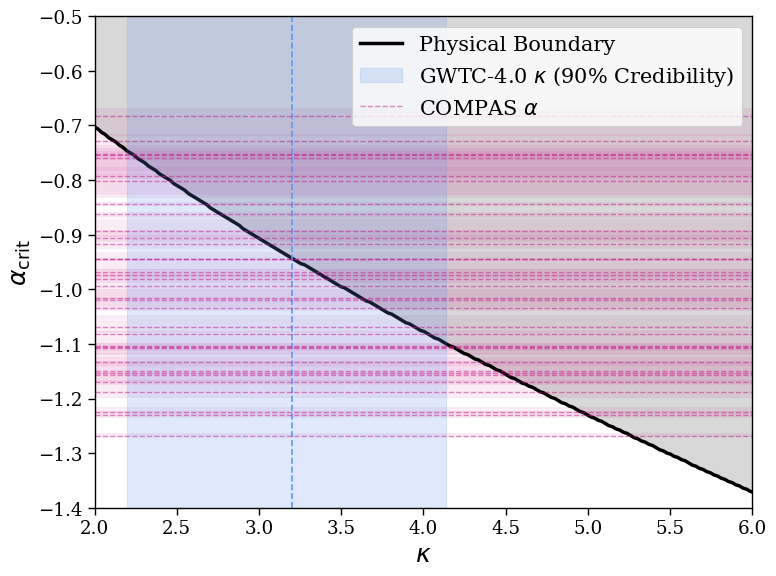

In [67]:
plt.figure(figsize=(8, 6))
plt.plot(kappa_grid, alpha_crit, color='black', lw=2.5, label='Physical Boundary')
plt.fill_between(kappa_grid, alpha_crit, -0.5, color='gray', alpha=0.3)
plt.axvspan(kappa_lo, kappa_hi, color='cornflowerblue', alpha=0.2, label=r'GWTC-4.0 $\kappa$ (90% Credibility)', zorder=2)
plt.axvline(kappa_med, color='cornflowerblue', ls='--', zorder=2)
for i in range(len(models)):
    plt.axhline(alpha_med[i], color='mediumvioletred', ls='--', alpha=0.5, lw=1, label=r'COMPAS $\alpha$' if i == 0 else None)
    plt.axhspan(alpha_lo[i], alpha_hi[i], color='mediumvioletred', alpha=0.08, lw=0)
plt.xlabel(r'$\kappa$', fontsize=18)
plt.ylabel(r'$\alpha_\mathrm{crit}$', fontsize=18)
plt.xlim(2, 6)
plt.ylim(-1.4, -0.5)
plt.legend(loc='best', fontsize=15)
plt.tight_layout()
plt.savefig('figures/alpha_v_kappa.png', dpi=300, bbox_inches='tight')
plt.show()

Compatibility P (Eq. 8), the fraction of GWTC-4.0 draws with a non-negative formation rate over 0.1 < z < 1.5, for power laws and each boundary condition R_merge(z > 1.5), and for the COMPAS models.

In [68]:
alpha_grid = np.round(np.arange(-3.0, -0.5 + 1e-9, 0.01), 2)
boundaries = [0, 100, 200, 300, 400, 500]       # R_merge(z > 1.5) [Gpc^-3 yr^-1]

P_pl = {}
for c in boundaries:
    Rm = grid.merger_rate(rates_O4, boundary=c)
    P_pl[c] = np.array([grid.compatibility(grid.forward_matrix(grid.powerlaw_kernel(a)), Rm) for a in alpha_grid])

# COMPAS, fiducial metallicity history: which draws each model allows
flags = {m: grid.is_physical(solve(compas_matrix(m), Rm0)) for m in models}
P_compas = np.array([flags[m].mean() for m in models])

for c in boundaries:
    print(f"R_merge(z>1.5) = {c:>3}: P > 0.95 for alpha < {alpha_at(alpha_grid, P_pl[c], 0.95):.2f}, "
          f"P < 0.05 for alpha > {alpha_at(alpha_grid, P_pl[c], 0.05):.2f}")
print(f"\nCOMPAS models with alpha < -1.2: P = {np.round(np.sort(P_compas[alpha_med < -1.2]), 2)}")
print(f"COMPAS models with alpha > -0.85: P = {np.round(np.sort(P_compas[alpha_med > -0.85]), 2)}")

R_merge(z>1.5) =   0: P > 0.95 for alpha < -1.12, P < 0.05 for alpha > -0.70
R_merge(z>1.5) = 100: P > 0.95 for alpha < -1.32, P < 0.05 for alpha > -0.85
R_merge(z>1.5) = 200: P > 0.95 for alpha < -1.72, P < 0.05 for alpha > -0.96
R_merge(z>1.5) = 300: P > 0.95 for alpha < -1.95, P < 0.05 for alpha > -1.05
R_merge(z>1.5) = 400: P > 0.95 for alpha < -2.11, P < 0.05 for alpha > -1.12
R_merge(z>1.5) = 500: P > 0.95 for alpha < -2.23, P < 0.05 for alpha > -1.17

COMPAS models with alpha < -1.2: P = [0.94 0.94 0.95]
COMPAS models with alpha > -0.85: P = [0.18 0.23 0.27 0.32 0.34 0.35 0.37 0.39]


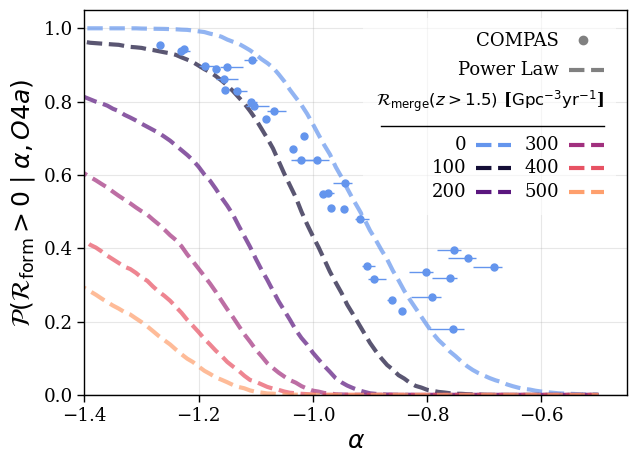

In [69]:
def legend_row(label, color, marker=None, ls=None):
    # one right-aligned legend row: text followed by a symbol
    draw = DrawingArea(30, 15, 0, 0)
    if marker:
        draw.add_artist(mlines.Line2D([15], [7.5], color=color, marker=marker, markersize=6))
    if ls:
        draw.add_artist(mlines.Line2D([5, 30], [7.5, 7.5], color=color, linestyle=ls, lw=3))
    return HPacker(children=[TextArea(label, textprops=dict(size=13, ha='right')), draw], align='center', pad=0, sep=2)

colors = dict(zip(boundaries, ['cornflowerblue'] + list(plt.cm.magma(np.linspace(0.1, 0.8, 5)))))

plt.figure(figsize=(7, 5))
plt.errorbar(alpha_med, P_compas, xerr=[alpha_med - alpha_lo, alpha_hi - alpha_med],
             fmt='o', color='cornflowerblue', ms=5, elinewidth=1, capsize=0, zorder=10)
for c in boundaries:
    plt.plot(alpha_grid, P_pl[c], color=colors[c], ls='--', lw=3, alpha=0.7)

# legend: symbols, then the boundary conditions in two columns
header = TextArea(r'$\mathcal{R}_{\mathrm{merge}}(z>1.5)$ [$\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}$]', textprops=dict(size=12, ha='center', weight='bold'))
rule = DrawingArea(160, 2, 0, 0)
rule.add_artist(mlines.Line2D([0, 160], [0, 0], color='black', lw=1))
cols = [VPacker(children=[legend_row(str(c), colors[c], ls='--') for c in half], align='right', pad=0, sep=2)
        for half in (boundaries[:3], boundaries[3:])]
box = VPacker(children=[legend_row('COMPAS', 'grey', marker='o'), legend_row('Power Law', 'grey', ls='--'), header, rule,
                        HPacker(children=cols, align='baseline', pad=0, sep=10)], align='right', pad=5, sep=6)
legend = AnchoredOffsetbox(loc='upper right', child=box, pad=0.3, frameon=True, bbox_to_anchor=(0.98, 0.98),
                           bbox_transform=plt.gca().transAxes, borderpad=0.)
legend.patch.set_facecolor('white')
legend.patch.set_alpha(0.6)
legend.patch.set_edgecolor('none')
plt.gca().add_artist(legend)

plt.axhline(0, color='black', lw=1, alpha=0.3)
plt.xlabel(r'$\alpha$', fontsize=18)
plt.ylabel(r'$\mathcal{P}(\mathcal{R}_{\mathrm{form}}>0 \mid \alpha, O4a)$', fontsize=18)
plt.grid(alpha=0.3)
plt.ylim(0, 1.05)
plt.xlim(-1.4, -0.45)
plt.savefig('figures/passrate_vs_alpha.png', dpi=300, bbox_inches='tight')
plt.show()

# Population synthesis

Fig. 5: compatibility of the COMPAS models that vary only the mass transfer efficiency beta (Section 4.2).

beta = 0.0 : P = 0.641
beta = 0.25: P = 0.705
beta = 0.5 : P = 0.550
beta = 0.75: P = 0.352
beta = 1.0 : P = 0.317


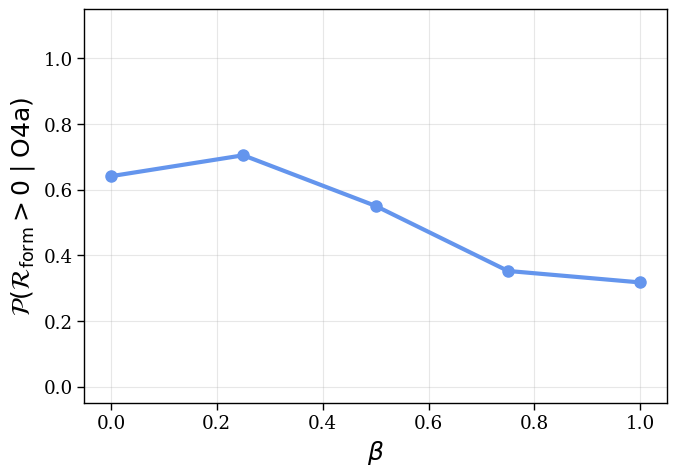

In [70]:
betas = [0.0, 0.25, 0.5, 0.75, 1.0]
P_beta = [P_compas[models.index(f'faccFIXEDbeta{b}zetaHG6.0RemMassFRYER2012SNDELAYED')] for b in betas]
for b, P in zip(betas, P_beta):
    print(f"beta = {b:<4}: P = {P:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(betas, P_beta, 'o-', color='cornflowerblue', lw=3, markersize=8)
ax.set_xlabel(r'$\beta$', fontsize=18)
ax.set_ylabel(r'$\mathcal{P}(\mathcal{R}_{\mathrm{form}}>0 \mid \mathrm{O4a})$', fontsize=18)
ax.set_ylim(-0.05, 1.15)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/popsynth.png', dpi=300, bbox_inches='tight')
plt.show()

# Merger rate

Fig. 6: GWTC-4.0 draws coloured by the fraction of COMPAS models they are compatible with (Section 4.3). Weighting the draws by this fraction tightens the merger rate at z = 1.5.

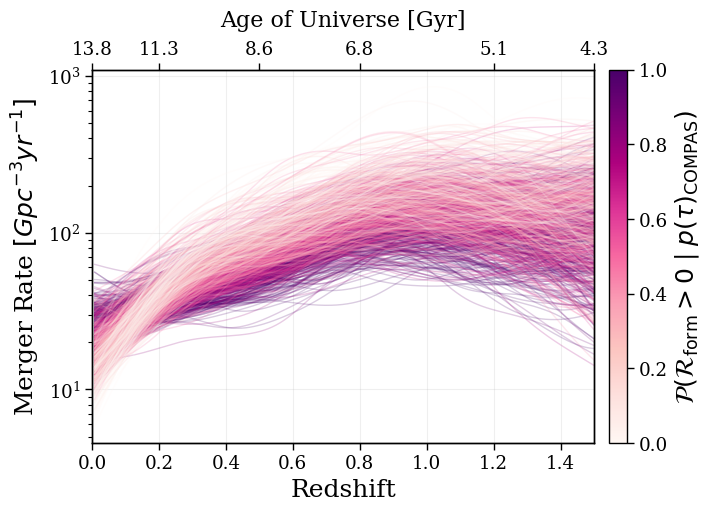

In [71]:
pass_frac = np.mean([flags[m] for m in models], axis=0)     # per draw

rng = np.random.default_rng(2)
sample = rng.choice(n_draws, size=1000, replace=False)
sample = sample[np.argsort(pass_frac[sample])[::-1]]          # most compatible drawn first
cmap = cm.RdPu
norm = mcolors.Normalize(vmin=pass_frac.min(), vmax=pass_frac.max())

fig, ax1 = plt.subplots(figsize=(7, 5), constrained_layout=True)
for i in sample:
    ax1.plot(zs_O4, rates_O4[:, i], color=cmap(norm(pass_frac[i])), alpha=0.2, lw=1)
ax2 = ax1.twiny()
ax2.set_xlim(0, 1.5)
ax2.set_xticks(z_ticks)
ax2.set_xticklabels([f'{cosmo.age(z).to_value(u.Gyr):.1f}' for z in z_ticks])
ax2.set_xlabel('Age of Universe [Gyr]', fontsize=16, labelpad=10)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax1, shrink=1, pad=0.00)
cbar.set_label(r'$\mathcal{P}(\mathcal{R}_{\mathrm{form}}>0 \mid p(\tau)_\mathrm{COMPAS})$', fontsize=18)
ax1.set_yscale('log')
ax1.set_xlim(0, 1.5)
ax1.set_xlabel('Redshift', fontsize=18)
ax1.set_ylabel(r'Merger Rate $[Gpc^{-3} yr^{-1}]$', fontsize=18)
ax1.grid(alpha=0.2)
plt.savefig('figures/merger_rates.png', dpi=300, bbox_inches='tight')
plt.show()

In [72]:
# merger rate at z = 1.5 before and after weighting by COMPAS compatibility
i15 = np.argmin(np.abs(zs_O4 - 1.5))
lo, med, up = np.percentile(rates_O4[i15], [5, 50, 95])
lo_w, med_w, up_w = weighted_percentiles(rates_O4[i15], pass_frac)
print(f"z = {zs_O4[i15]:.2f}, 90% upper bound: {up:.0f} -> {up_w:.0f} Gpc^-3 yr^-1 ({(up_w / up - 1) * 100:+.0f}%)")
print(f"z = {zs_O4[i15]:.2f}, median: {med:.0f} -> {med_w:.0f} Gpc^-3 yr^-1")

z = 1.50, 90% upper bound: 334 -> 276 Gpc^-3 yr^-1 (-17%)
z = 1.50, median: 122 -> 109 Gpc^-3 yr^-1
